
# RouteVoice — Logistics Voice AI Agent Call Quality & Containment Analytics

**What this is:** a voice-AI monitoring system for Portside AI, a
fictional logistics platform whose voice agent calls truck drivers for
ETA check-ins, exception reports, proof-of-delivery confirmation, and
reschedule requests — the "voice/multimodal AI agent" trend, where the
telemetry that matters (transcription confidence, interruptions,
turn-taking latency) doesn't exist for a text-only AI product.

**The finding this uncovers:** a voice-model backbone upgrade (v1 → v2)
looks like a clean nationwide win — containment up +4.94pp (p<0.001).
But **Appalachian**, roughly 20% of call volume, actually **regresses**
(−6.75pp, p=3.6×10⁻⁶) over the same release, while every other region
improves. A companion logistic regression shows transcription confidence
is by far the dominant driver of containment (odds ratio ≈17.7), and
Appalachian's confidence is the one region that *fell* in this release —
consistent with a regional/dialectal coverage gap in the new voice
model's training data, a well-documented real category of voice-AI
fairness risk. This project also demonstrates two other detector shapes:
a transient shared-infrastructure ASR outage, and a benign deploy the
agent correctly declines to flag.

**On the LLM backend:** same cached/live design as the rest of this
session's AI-augmented projects — see `../shared/llm_client.py`.


In [1]:

import sys, json
sys.path.insert(0, "../../shared")
sys.path.insert(0, "../pipeline")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from voice_metrics import containment_summary, containment_shift_test
from call_anomaly import hourly_confidence_series, point_anomaly_detector, find_anomaly_windows
from regression_analysis import fit_containment_model, standardized_effect_summary
from agent import review_regional_deploy, review_asr_outage, review_benign_deploy
from llm_client import get_client

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

calls = pd.read_csv("../data/calls.csv", parse_dates=["timestamp"])
client = get_client(cache_file="../cached_responses.json")

print(f"{len(calls):,} calls | {calls.timestamp.min()} to {calls.timestamp.max()} | "
      f"5 regions | model deploy 2026-05-26 | ASR outage 2026-05-13 | benign deploy 2026-06-05")
calls.head()


20,000 calls | 2026-05-01 00:04:30 to 2026-06-19 23:53:10 | 5 regions | model deploy 2026-05-26 | ASR outage 2026-05-13 | benign deploy 2026-06-05


,call_id,timestamp,call_type,driver_region,model_version,call_duration_sec,transcription_confidence,n_interruptions,avg_response_latency_ms,escalated_to_human,outcome_success,driver_sentiment_score
0,C918800,2026-05-01 00:04:30,exception_report,Pacific_Northwest,v1,112.1,0.799,0,1013.3,True,True,3
1,C910533,2026-05-01 00:06:36,eta_checkin,Appalachian,v1,52.4,0.877,1,1103.6,True,True,3
2,C917665,2026-05-01 00:07:39,pod_confirmation,Appalachian,v1,45.9,0.728,2,840.8,False,True,4
3,C908942,2026-05-01 00:28:14,reschedule_request,Northeast,v1,94.2,0.823,0,774.8,False,True,4
4,C912842,2026-05-01 00:28:40,reschedule_request,Midwest,v1,105.9,0.926,1,994.0,True,True,4


## 1. Nationwide Aggregate vs. Regional Reality

In [2]:

national = containment_shift_test(calls, region=None)
regions = ["Midwest", "Gulf_Coast", "Northeast", "Pacific_Northwest", "Appalachian"]
regional_results = pd.DataFrame([vars(containment_shift_test(calls, r)) for r in regions], index=regions)
print("Nationwide:", national)
regional_results


Nationwide: ContainmentTestResult(p_before=0.7552, p_after=0.8046, lift_pp=4.94, z=np.float64(8.426), p_value=np.float64(0.0), n_before=9960, n_after=10040, significant=True)


,p_before,p_after,lift_pp,z,p_value,n_before,n_after,significant
Midwest,0.7597,0.8566,9.68,9.463,0.000000e+00,2851,3040,True
Gulf_Coast,0.7423,0.8063,6.40,4.851,1.229067e-06,2018,2003,True
Northeast,0.8048,0.8640,5.92,4.416,1.007254e-05,1537,1537,True
Pacific_Northwest,0.7640,0.8411,7.71,5.254,1.484298e-07,1483,1466,True
Appalachian,0.7185,0.6510,-6.75,-4.636,3.556066e-06,2071,1994,True


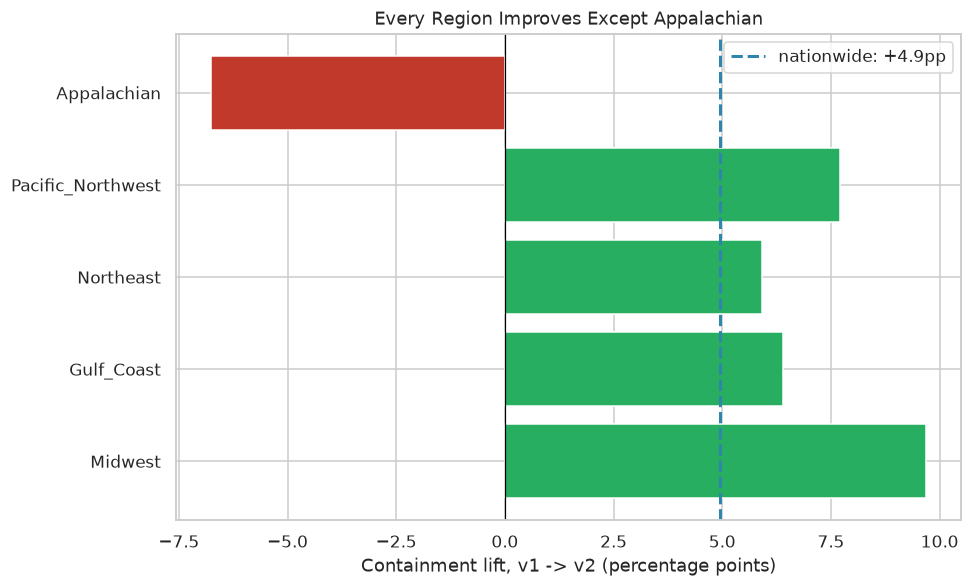

In [3]:

fig, ax = plt.subplots(figsize=(9, 5.5))
colors = ["#27AE60" if lp > 0 else "#C0392B" for lp in regional_results.lift_pp]
ax.barh(regional_results.index, regional_results.lift_pp, color=colors)
ax.axvline(national.lift_pp, color="#2E86AB", linestyle="--", linewidth=2, label=f"nationwide: +{national.lift_pp:.1f}pp")
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Containment lift, v1 -> v2 (percentage points)")
ax.set_title("Every Region Improves Except Appalachian")
ax.legend()
plt.tight_layout()
plt.savefig("../dashboard/regional_lift.png", dpi=150)
plt.show()


The nationwide number (+4.94pp) sits comfortably inside the range
of the four improving regions — nothing about the aggregate signals a
problem. Appalachian's −6.75pp is the only bar pointing the wrong way,
and it's completely invisible unless you deliberately look region by
region.

## 2. What's Actually Driving Containment? A Regression, Not Just a Correlation

In [4]:

model = fit_containment_model(calls)
effects = standardized_effect_summary(model)
effects


,coef,odds_ratio,p_value,ci_low,ci_high
const,-1.1193,0.326,0.0000,-1.5444,-0.6942
transcription_confidence,2.8758,17.740,0.0000,2.4849,3.2667
n_interruptions,-0.0128,0.987,0.3665,-0.0407,0.0150
avg_response_latency_ms,-0.0714,0.931,0.4238,-0.2463,0.1036


Transcription confidence is overwhelmingly the dominant driver of
containment (odds ratio ≈17.7, p<0.001) — interruption count and
response latency are not significant predictors once confidence is
accounted for. This turns "Appalachian is worse" into a testable
mechanism: if Appalachian's confidence fell, that alone would explain
its regression.

In [5]:

conf_by_region = containment_summary(calls, groupby=["driver_region", "model_version"])[["avg_confidence"]].unstack()
conf_by_region.columns = ["v1", "v2"]
conf_by_region["change"] = conf_by_region.v2 - conf_by_region.v1
conf_by_region.sort_values("change")


,v1,v2,change
driver_region,,,
Appalachian,0.8156,0.7102,-0.1054
Northeast,0.8867,0.9321,0.0454
Midwest,0.8731,0.9242,0.0511
Pacific_Northwest,0.8548,0.9081,0.0533
Gulf_Coast,0.8431,0.8986,0.0555


Confirmed: Appalachian is the only region where average
transcription confidence *fell* (0.82 → 0.71) — every other region's
confidence rose. Combined with the regression result above, this is a
coherent, evidence-backed mechanism, not a coincidence.

## 3. The Transient ASR Outage — a Different Signal Shape Entirely

In [6]:

hourly = hourly_confidence_series(calls)
anomalies = point_anomaly_detector(hourly)
outage_windows = find_anomaly_windows(anomalies)
outage_windows


,start,end,duration_hours,peak_z_score,trough_confidence,direction
0,2026-05-13 10:00:00,2026-05-13 13:00:00,4,14.098944,0.377667,drop


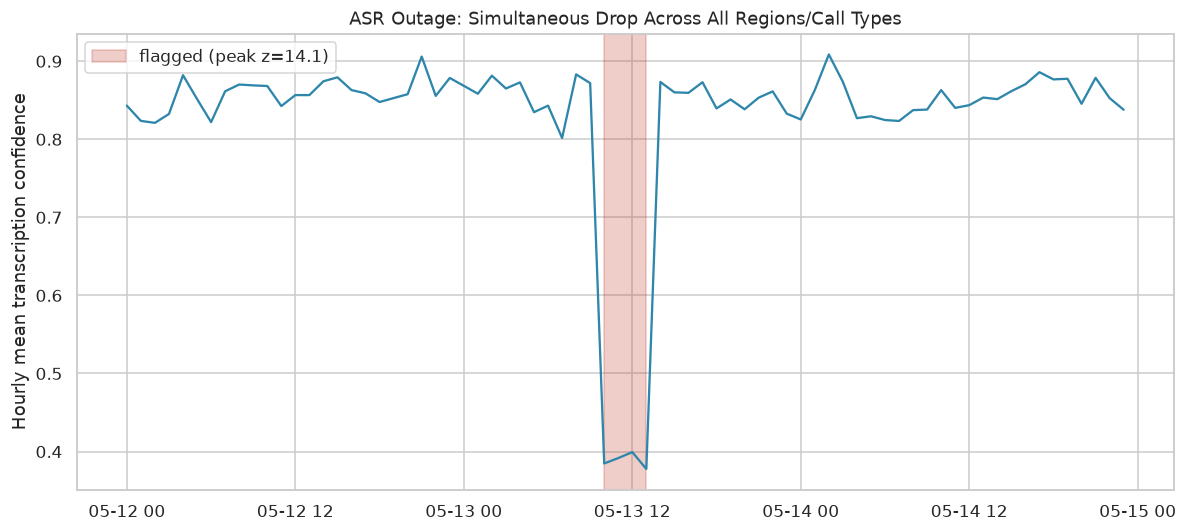

In [7]:

fig, ax = plt.subplots(figsize=(11, 5))
window = hourly.loc["2026-05-12":"2026-05-14"]
ax.plot(window.index, window.values, color="#2E86AB", linewidth=1.5)
if len(outage_windows):
    w = outage_windows.iloc[0]
    ax.axvspan(w.start, w.end, color="#C0392B", alpha=0.25, label=f"flagged (peak z={w.peak_z_score:.1f})")
    ax.legend()
ax.set_ylabel("Hourly mean transcription confidence")
ax.set_title("ASR Outage: Simultaneous Drop Across All Regions/Call Types")
plt.tight_layout()
plt.savefig("../dashboard/asr_outage.png", dpi=150)
plt.show()


A sharp, ~4-hour, all-region drop with no deploy behind it — the
signature of a shared upstream infrastructure incident, not a model or
fairness issue. This is deliberately a different shape than the
Appalachian finding: sudden and universal, versus gradual-looking-but-
actually-instant-at-deploy and region-specific.

## 4. The Benign Deploy — Correctly Not Flagged

In [8]:

benign_report = review_benign_deploy(calls, pd.Timestamp("2026-06-05"), window_days=3, client=client)
print(benign_report.evidence)
print()
print(benign_report.narrative)


{'duration_before_sec': np.float64(86.4), 'duration_after_sec': np.float64(71.8), 'containment_before': 0.8062, 'containment_after': 0.8052, 'z': np.float64(-0.061), 'p_value': np.float64(0.9509744129317177)}

VERDICT: Benign / no action

EVIDENCE: Average call duration fell substantially (86.4s -> 71.8s, about -17%) following the shortened-greeting-script deploy, but containment showed no significant change (80.6% -> 80.5%, z=-0.06, p=0.95) -- the outcome metric that actually defines call success is unaffected.

RECOMMENDED ACTION: No action required. Log this as a confirmed efficiency win (shorter average call time with no containment cost); a monitoring rule that flags any large metric change as a regression would have false-alarmed on the duration drop here.


## 5. Agent Reports

In [9]:

regional_reports = {r: review_regional_deploy(calls, r, client) for r in regions}
print(regional_reports["Appalachian"].narrative)


VERDICT: Incident -- fairness/coverage risk, not excused by the national number

EVIDENCE: Nationwide containment rose +4.94pp (75.5% -> 80.5%, p<0.001) -- a clean-looking release. But Appalachian containment FELL from 71.9% to 65.1% (-6.75pp, z=-4.64, p=3.6x10^-6) over the same release, moving in the opposite direction of every other region and of the nationwide number it's part of. Appalachian is roughly 20% of call volume, which is enough to be a real, statistically unambiguous regression but not enough to move the nationwide aggregate into negative territory -- it is fully hidden unless a reviewer specifically slices by region.

LIKELY MECHANISM: a companion regression analysis (logistic regression of containment on transcription confidence, interruption count, and response latency) finds transcription confidence is by far the dominant driver of containment (odds ratio ~17.7 per unit of confidence, p<0.001; interruptions and latency are not significant predictors once confidence is

In [10]:

print(regional_reports["Midwest"].narrative)


VERDICT: Genuine improvement

EVIDENCE: Midwest containment rose from 76.0% to 85.7% (v1->v2, +9.68pp, z=9.46, p<0.001), a larger improvement than the +4.94pp nationwide aggregate -- Midwest, the largest-volume region, is a major contributor to the nationwide win, not a passenger riding on other regions' gains.

RECOMMENDED ACTION: No action needed; confirmed improvement.


In [11]:

asr_report = review_asr_outage(outage_windows.iloc[0].to_dict(), client)
print(asr_report.narrative)


VERDICT: Incident -- transient, infrastructure

EVIDENCE: A sharp, simultaneous drop in transcription confidence (peak z-score ≈14.1, confidence falling to ~0.38 at the trough) is detected across a ~4-hour window (2026-05-13, 10:00-13:00) with no model deploy or region-specific pattern tied to it -- the drop is broad and shared, the signature of a common upstream dependency (most likely the speech-recognition provider) rather than anything model- or region-specific.

LIKELY MECHANISM: not determinable from call-level telemetry alone; this playbook does not have direct ASR-provider status/infra logs to confirm the exact upstream component.

RECOMMENDED ACTION: File as a resolved transient infra incident given the sharp recovery after the window; pull ASR-provider status/incident logs for the window to confirm root cause and evaluate whether a fallback ASR path is warranted for future provider-side outages.


## 6. Summary

In [12]:

print("=== RouteVoice summary ===")
for r in regions:
    print(f"{r:20s} -> {regional_reports[r].verdict}")
print(f"{'ASR outage':20s} -> {asr_report.verdict}")
print(f"{'benign deploy':20s} -> {benign_report.verdict}")
print()
print("The finding that matters most: a voice-model release looked like a clean nationwide win")
print("(+4.94pp containment, p<0.001) while Appalachian -- ~20% of volume -- regressed -6.75pp (p=3.6e-6),")
print("driven by a fall in transcription confidence consistent with a regional dialect coverage gap in the")
print("new model. A regression analysis confirms confidence is the dominant driver of containment, giving")
print("this finding an evidence-backed mechanism rather than just a flagged number.")


=== RouteVoice summary ===
Midwest              -> GENUINE_IMPROVEMENT
Gulf_Coast           -> GENUINE_IMPROVEMENT
Northeast            -> GENUINE_IMPROVEMENT
Pacific_Northwest    -> GENUINE_IMPROVEMENT
Appalachian          -> INCIDENT_FAIRNESS_RISK
ASR outage           -> INCIDENT_TRANSIENT
benign deploy        -> BENIGN_NO_ACTION

The finding that matters most: a voice-model release looked like a clean nationwide win
(+4.94pp containment, p<0.001) while Appalachian -- ~20% of volume -- regressed -6.75pp (p=3.6e-6),
driven by a fall in transcription confidence consistent with a regional dialect coverage gap in the
new model. A regression analysis confirms confidence is the dominant driver of containment, giving
this finding an evidence-backed mechanism rather than just a flagged number.
